In [18]:
%pip install pyopensky pandas
%pip install matplotlib seaborn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Exploratory

In [19]:
import json
import os
from pyopensky.rest import REST

# Setup & Connexion
with open("credentials.json", "r") as f:
    creds = json.load(f)

os.environ["OPENSKY_CLIENT_ID"] = creds["clientId"]
os.environ["OPENSKY_CLIENT_SECRET"] = creds["clientSecret"]

rest = REST()
df = rest.states()

# 1. Liste des colonnes et types
print("=== INFORMATIONS SUR LE DATASET ===")
print(df.info())

# 2. Statistiques descriptives sur les variables numériques
print("\n=== STATISTIQUES DESCRIPTIVES ===")
print(df.describe().T[['mean', 'std', 'min', '50%', 'max']])

# 3. Taux de valeurs manquantes par colonne (%)
print("\n=== VALEURS MANQUANTES (%) ===")
print((df.isnull().sum() / len(df) * 100).round(2))

=== INFORMATIONS SUR LE DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12501 entries, 0 to 12500
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   icao24           12501 non-null  string[pyarrow]    
 1   callsign         12501 non-null  string[pyarrow]    
 2   origin_country   12501 non-null  string[pyarrow]    
 3   last_position    12432 non-null  datetime64[ns, UTC]
 4   timestamp        12501 non-null  datetime64[ns, UTC]
 5   longitude        12432 non-null  double[pyarrow]    
 6   latitude         12432 non-null  double[pyarrow]    
 7   altitude         11212 non-null  double[pyarrow]    
 8   onground         12501 non-null  bool[pyarrow]      
 9   groundspeed      12499 non-null  double[pyarrow]    
 10  track            12501 non-null  double[pyarrow]    
 11  vertical_rate    11243 non-null  double[pyarrow]    
 12  sensors          0 non-null      null[

=== RÉPARTITION EN VOL / AU SOL (%) ===
onground
False    90.040797
True      9.959203
Name: proportion, dtype: double[pyarrow]


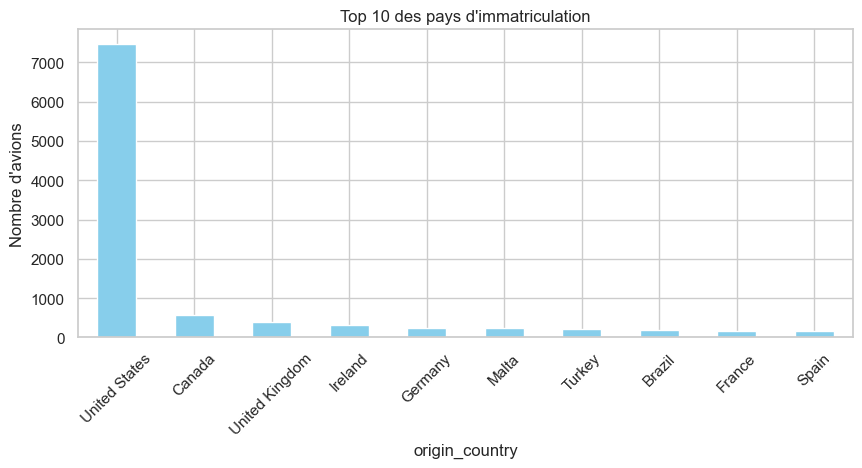

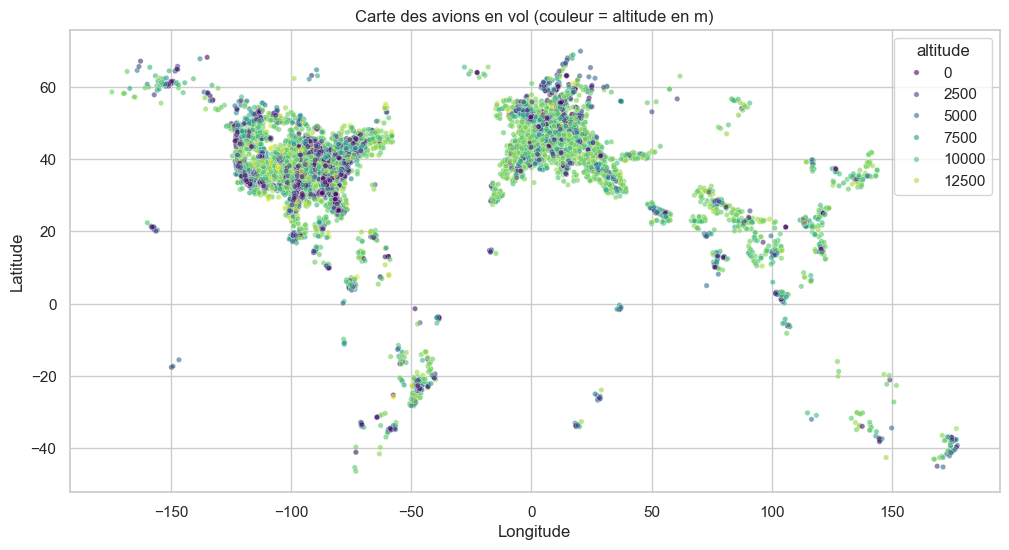

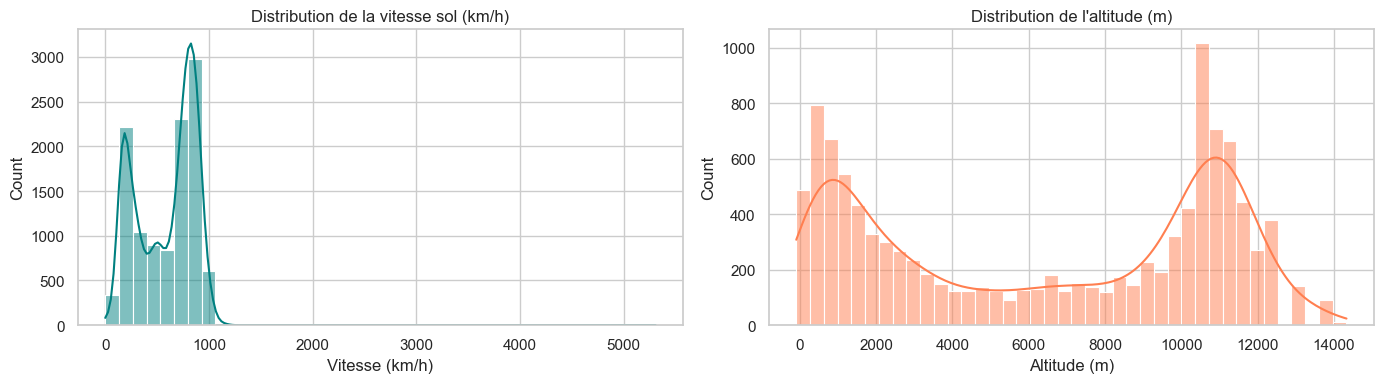

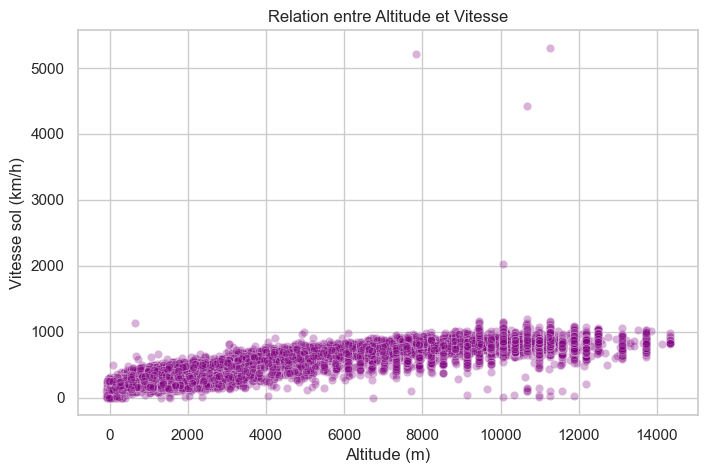

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Conversion des types PyArrow vers float64 standard pour la compatibilité Seaborn
cols_numeriques = ['longitude', 'latitude', 'altitude', 'groundspeed', 'track', 'vertical_rate', 'geoaltitude']
for col in cols_numeriques:
    if col in df.columns:
        df[col] = df[col].astype('float64')

# 2. Conversion de la vitesse en km/h
df['groundspeed_kmh'] = df['groundspeed'] * 3.6

# --- A. Répartition Sol vs Vol ---
print("=== RÉPARTITION EN VOL / AU SOL (%) ===")
print(df['onground'].value_counts(normalize=True) * 100)

# --- B. Top 10 des pays d'origine ---
plt.figure(figsize=(10, 4))
df['origin_country'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title("Top 10 des pays d'immatriculation")
plt.ylabel("Nombre d'avions")
plt.xticks(rotation=45)
plt.show()

# --- C. Carte 2D des positions géographiques ---
plt.figure(figsize=(12, 6))
vols_en_air = df[df['onground'] == False]

sns.scatterplot(
    data=vols_en_air, 
    x='longitude', 
    y='latitude', 
    hue='altitude', 
    palette='viridis', 
    s=15, 
    alpha=0.6
)
plt.title("Carte des avions en vol (couleur = altitude en m)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# --- D. Distributions de la vitesse et de l'altitude ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(vols_en_air['groundspeed_kmh'].dropna(), bins=40, kde=True, ax=axes[0], color='teal')
axes[0].set_title("Distribution de la vitesse sol (km/h)")
axes[0].set_xlabel("Vitesse (km/h)")

sns.histplot(vols_en_air['altitude'].dropna(), bins=40, kde=True, ax=axes[1], color='coral')
axes[1].set_title("Distribution de l'altitude (m)")
axes[1].set_xlabel("Altitude (m)")

plt.tight_layout()
plt.show()

# --- E. Relation Altitude vs Vitesse ---
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=vols_en_air,
    x='altitude',
    y='groundspeed_kmh',
    alpha=0.3,
    color='purple'
)
plt.title("Relation entre Altitude et Vitesse")
plt.xlabel("Altitude (m)")
plt.ylabel("Vitesse sol (km/h)")
plt.show()